# Isolation forest model 

This notebook is for testing and evaluating the **Isolation forest model** on the timestamped feature table built in [03_feature_engineering.ipynb](/notebooks/03_feature_engineering.ipynb). It loads the same three Nginx log sources, builds `features_df`, fit & predict model (with multiple experementations).

# 1. Setup and input data

In [140]:
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

project_root = Path.cwd().parent 
sys.path.append(str(project_root))

from src.fink_api_anomaly_detection.models import IsolationForestDetector
from src.fink_api_anomaly_detection.utils.plot_utils import plot_anomaly_timeline, plot_anomaly_overlap, plot_anomaly_features

from src.fink_api_anomaly_detection.data.raw_logs import ls_log_files
from src.fink_api_anomaly_detection.preprocess.nginx_logs.access_logs import build_access_dataframe
from src.fink_api_anomaly_detection.preprocess.nginx_logs.error_logs import build_error_dataframe
from src.fink_api_anomaly_detection.preprocess.nginx_logs.geo_logs import build_geo_dataframe
from src.fink_api_anomaly_detection.features.nginx_logs import build_temporal_features, build_feature_subsets


DATA_DIR = project_root / "data" / "nginx_history_logs"
print(f"Dataset directory: {DATA_DIR.resolve()}")

Dataset directory: /home/machter-l/fink-api-forecasting-anomaly-detection/data/nginx_history_logs


Listing of available logs files (per category):

In [2]:
access_files = ls_log_files(DATA_DIR, "access-logs")
geo_files = ls_log_files(DATA_DIR, "geo-logs")
error_files = ls_log_files(DATA_DIR, "error-logs")

Parsing the raw logs into Dataframes can take a few minutes. 

In [3]:
access_df = build_access_dataframe(access_files)
geo_df = build_geo_dataframe(geo_files)
errors_df = build_error_dataframe(error_files)

print(f"access_df.shape: {access_df.shape}")
print(f"geo_df.shape: {geo_df.shape}")
print(f"errors_df.shape: {errors_df.shape}")

access_df.shape: (1005103, 16)
geo_df.shape: (1005103, 6)
errors_df.shape: (833, 17)


# 2. Feature engineering and validation

The next cell follows notebook 03 and builds one row per  each 5-minute window : 

In [31]:
features_df = build_temporal_features(access_df, geo_df, errors_df)
features_df = features_df[:-1]  # Remove last row to avoid 2026-10-17 00:00:00+00:00 last value no (no in 1-14 days) in features
print(f"Feature table shape: {features_df.shape}")
print(f"Time span: {features_df['timestamp'].min()} to {features_df['timestamp'].max()}")
display(features_df.head())
display(features_df.tail())

Feature table shape: (4032, 24)
Time span: 2026-10-03 00:00:00+00:00 to 2026-10-16 23:55:00+00:00


,timestamp,request_count,get_count,post_count,http_4xx_count,http_5xx_count,http_4xx_rate,http_5xx_rate,unique_client_count,bytes_sent_sum,...,nginx_broken_pipe_count,unique_country_count,top_country_share,top_country_share_without_france,endpoint_api_count,endpoint_unrecognized_count,unique_endpoint_count,request_count_delta,http_5xx_rate_delta,nginx_error_count_delta
0,2026-10-03 00:00:00+00:00,30,1,29,0,2,0.0,0.066667,6,1197413,...,0,3,0.600000,0,30,0,4,0.0,0.0,0.0
1,2026-10-03 00:05:00+00:00,36,0,36,0,0,0.0,0.0,4,3077416,...,0,3,0.472222,0,36,0,4,6.0,-0.066667,0.0
2,2026-10-03 00:10:00+00:00,353,1,352,0,0,0.0,0.0,9,83959825,...,0,4,0.929178,0,353,0,4,317.0,0.0,0.0
3,2026-10-03 00:15:00+00:00,363,1,362,0,0,0.0,0.0,9,100850864,...,0,4,0.851240,0,363,0,5,10.0,0.0,0.0
4,2026-10-03 00:20:00+00:00,327,2,325,1,4,0.003058,0.012232,8,72522424,...,1,3,0.935583,0,326,1,5,-36.0,0.012232,2.0


,timestamp,request_count,get_count,post_count,http_4xx_count,http_5xx_count,http_4xx_rate,http_5xx_rate,unique_client_count,bytes_sent_sum,...,nginx_broken_pipe_count,unique_country_count,top_country_share,top_country_share_without_france,endpoint_api_count,endpoint_unrecognized_count,unique_endpoint_count,request_count_delta,http_5xx_rate_delta,nginx_error_count_delta
4027,2026-10-16 23:35:00+00:00,41,3,38,0,0,0.0,0.0,5,255428,...,0,3,0.536585,0,41,0,8,-47.0,0.0,0.0
4028,2026-10-16 23:40:00+00:00,44,2,42,0,0,0.0,0.0,10,608838,...,0,3,0.772727,0,44,0,6,3.0,0.0,0.0
4029,2026-10-16 23:45:00+00:00,79,4,75,0,0,0.0,0.0,8,1021306,...,0,4,0.772152,0,76,3,9,35.0,0.0,0.0
4030,2026-10-16 23:50:00+00:00,71,4,67,0,2,0.0,0.028169,10,371111,...,0,3,0.563380,0,71,0,10,-8.0,0.028169,1.0
4031,2026-10-16 23:55:00+00:00,67,4,63,0,0,0.0,0.0,10,1450850,...,0,4,0.462687,0,67,0,7,-4.0,-0.028169,-1.0


Get independent copies for each subset features -- see (notebooks/03_features_engineering.ipynb) : 

In [70]:
feature_sets = build_feature_subsets(features_df)
subset_summary = pd.DataFrame(
    {
        "feature_count": {name: subset.shape[1] for name, subset in feature_sets.items()},
        "row_count": {name: len(subset) for name, subset in feature_sets.items()},
    }
)
display(subset_summary)


,feature_count,row_count
baseline,9,4032
baseline_nginx,14,4032
baseline_nginx_geography,17,4032
baseline_nginx_geography_endpoints,20,4032
all,23,4032



**Summary:** `features_df` is the complete timestamped 24 features dataset. `feature_sets` contains the five model input (Dataframes) configurations (`baseline`, `baseline_nginx`, `baseline_nginx_geography`, `baseline_nginx_geography_endpoints`, and `all`).

# 3. Experimental protocol: train and evaluation periods

**Temporal split (not random):** The first **50% of the chronological windows (days 1-7)** represents the train (reference) period, and the **last 50% (days 8-14)** form the evaluation (test) period. evaluation metrics are calculated exclusively on the test period .

In [71]:
timestamps = pd.to_datetime(features_df["timestamp"])

split_position = int(len(features_df) * 0.50)

train_index = features_df.index[:split_position]
eval_index = features_df.index[split_position:]

print("Training period:",len(train_index), "rows")
print(timestamps.iloc[0], "->", timestamps.iloc[split_position - 1])
print("------------------------------------------------------")
print("Evaluation period:", len(eval_index), "rows")
print(timestamps.iloc[split_position], "->", timestamps.iloc[-1])

Training period: 2016 rows
2026-10-03 00:00:00+00:00 -> 2026-10-09 23:55:00+00:00
------------------------------------------------------
Evaluation period: 2016 rows
2026-10-10 00:00:00+00:00 -> 2026-10-16 23:55:00+00:00


# 4. Baseline features experiment: an initial isoforest reference model

Here, we train the **Isolation Forest model using the 9 base features (df_b)**, and evaluate it on the test period (eval). This model will serve as a baseline, against which we can later test other isoforest models using the supersets of the base set features.

In [72]:
df_b = feature_sets["baseline"]
print(f"baseline features/columns: {df_b.columns.tolist()}")

baseline features/columns: ['request_count', 'get_count', 'post_count', 'http_4xx_count', 'http_5xx_count', 'http_4xx_rate', 'http_5xx_rate', 'unique_client_count', 'bytes_sent_sum']


In [73]:
X = df_b

X_train = X.loc[train_index]
X_eval = X.loc[eval_index]

isof_baseline = IsolationForestDetector() # default parameters: n_estimators=100, contamination='auto', random_state=42

isof_baseline.fit(X_train)
print(f"Model isoforest fitted with baselines features.")
# principale score evaluate the model on the evaluation sets
eval_results = isof_baseline.detect_anomalies(X_eval)

# additionally, we can also evaluate the model on the training set to see how many anomalies it detects there
train_results = isof_baseline.detect_anomalies(X_train)

print(f"Training periods: Number of anomalies detected: {int(train_results['is_anomaly'].sum())} out of {len(train_results)} total samples ({100 * train_results['is_anomaly'].mean():.2f}%)")
print(f"Evaluation periods: Number of anomalies detected: {int(eval_results['is_anomaly'].sum())} out of {len(eval_results)} total samples ({100 * eval_results['is_anomaly'].mean():.2f}%)") 

print("Anomalies detected in the evaluation period:")
eval_results[eval_results["is_anomaly"]==True].head(20)

Model isoforest fitted with baselines features.
Training periods: Number of anomalies detected: 169 out of 2016 total samples (8.38%)
Evaluation periods: Number of anomalies detected: 115 out of 2016 total samples (5.70%)
Anomalies detected in the evaluation period:


,request_count,get_count,post_count,http_4xx_count,http_5xx_count,http_4xx_rate,http_5xx_rate,unique_client_count,bytes_sent_sum,anomaly_label,anomaly_score,is_anomaly
2021,350,27,323,0,55,0.0,0.157143,8,143148325,-1,-0.054183,True
2038,604,27,577,0,108,0.0,0.178808,10,124195399,-1,-0.062212,True
2039,630,28,602,0,180,0.0,0.285714,12,106674568,-1,-0.113575,True
2041,570,27,543,0,84,0.0,0.147368,12,137640445,-1,-0.042456,True
2066,809,24,785,0,112,0.0,0.138443,17,104803558,-1,-0.098914,True
2068,624,25,599,0,69,0.0,0.110577,12,115093872,-1,-0.020511,True
2094,252,88,164,43,3,0.170635,0.011905,16,16473848,-1,-0.040825,True
2098,826,110,716,43,0,0.052058,0.0,12,57116235,-1,-0.056667,True
2177,306,168,138,71,4,0.232026,0.013072,14,7395864,-1,-0.094170,True
2185,177,72,105,49,6,0.276836,0.033898,12,1566344,-1,-0.071610,True


For example here, we can observe quickly that the Isolation Forest flags a consecutive sequence of evaluation windows, from index **2293 to 2300** (8 windows, 8*5min = 40 min), as anomalous. The HTTP 5xx rates during this interval also appear unusual, which may indicate a genuine anomaly rather than isolated model noise.

We also be observed that IsoForest detect a number of anomalies (8.38% train, 5.70% in test period) that is manageable for a human, unlike the baselines defined in 04_baselines_evaluation.ipynb (or the number of Windows systems detected is in the range of 40–50%). It might not mean anything for now, but one could argue that Isolation Forest is potentially better than the baselines, as it uses a combination of multiple features for prediction unlike the baselines, where the prediction depends on only a single feature.

# 5. Others Feature subset experiments

Which feature superset of baseline features produces interesting anomalies and provides complementary information ? 

to answer this question, we fit & evaluate a isoforest model on each feature superset; no changes to the hyperparameters for now; we begin by fixing the hyperparameters (using the defaults mentioned above).

In [84]:
feature_experiment_results = {}
feature_experiment_summary = []

for name, subset in feature_sets.items():
    X = subset

    X_train = X.loc[train_index]
    X_eval = X.loc[eval_index]

    isof = IsolationForestDetector()
    isof.fit(X_train)

    results_eval = isof.detect_anomalies(X_eval)
    results_train = isof.detect_anomalies(X_train)
    feature_experiment_results[name] = (results_train, results_eval)

    feature_experiment_summary.append({
        "feature_set": name,
        "n_features": X.shape[1],
        "n_train": len(X_train),
        "n_anomalies_train": int(results_train["is_anomaly"].sum()),
        "anomaly_rate_train": 100 * results_train["is_anomaly"].mean(),
        "n_eval": len(X_eval),
        "n_anomalies_eval": int(results_eval["is_anomaly"].sum()),
        "anomaly_rate_eval": 100 * results_eval["is_anomaly"].mean(),
    })

feature_experiment_summary = pd.DataFrame(feature_experiment_summary)
display(feature_experiment_summary.sort_values("anomaly_rate_eval", ascending=False))

,feature_set,n_features,n_train,n_anomalies_train,anomaly_rate_train,n_eval,n_anomalies_eval,anomaly_rate_eval
0,baseline,9,2016,169,8.382937,2016,115,5.704365
1,baseline_nginx,14,2016,167,8.283730,2016,87,4.315476
2,baseline_nginx_geography,17,2016,126,6.250000,2016,74,3.670635
3,baseline_nginx_geography_endpoints,20,2016,123,6.101190,2016,58,2.876984
4,all,23,2016,117,5.803571,2016,49,2.430556


The results highlight **a gradual decrease in the number of anomalies detected** by Isolation Forest as additional groups of features are incorporated. Over the evaluation period, the number of anomalies drops from 115/2016 for the `baseline` (9 features) to 49/2016 for the `all` configuration (23 features). This trend demonstrates that the representation of time windows significantly influences the model decisions. However, a reduction in the number of anomalies is not, in itself, sufficient to conclude that detection has improved. While additional features may provide useful supplementary information, they can also alter the data structure, thereby influencing the algorithm choices. Consequently, the next stage of the analysis should focus on visualizing the detected anomalies (in relation to time and traffic).

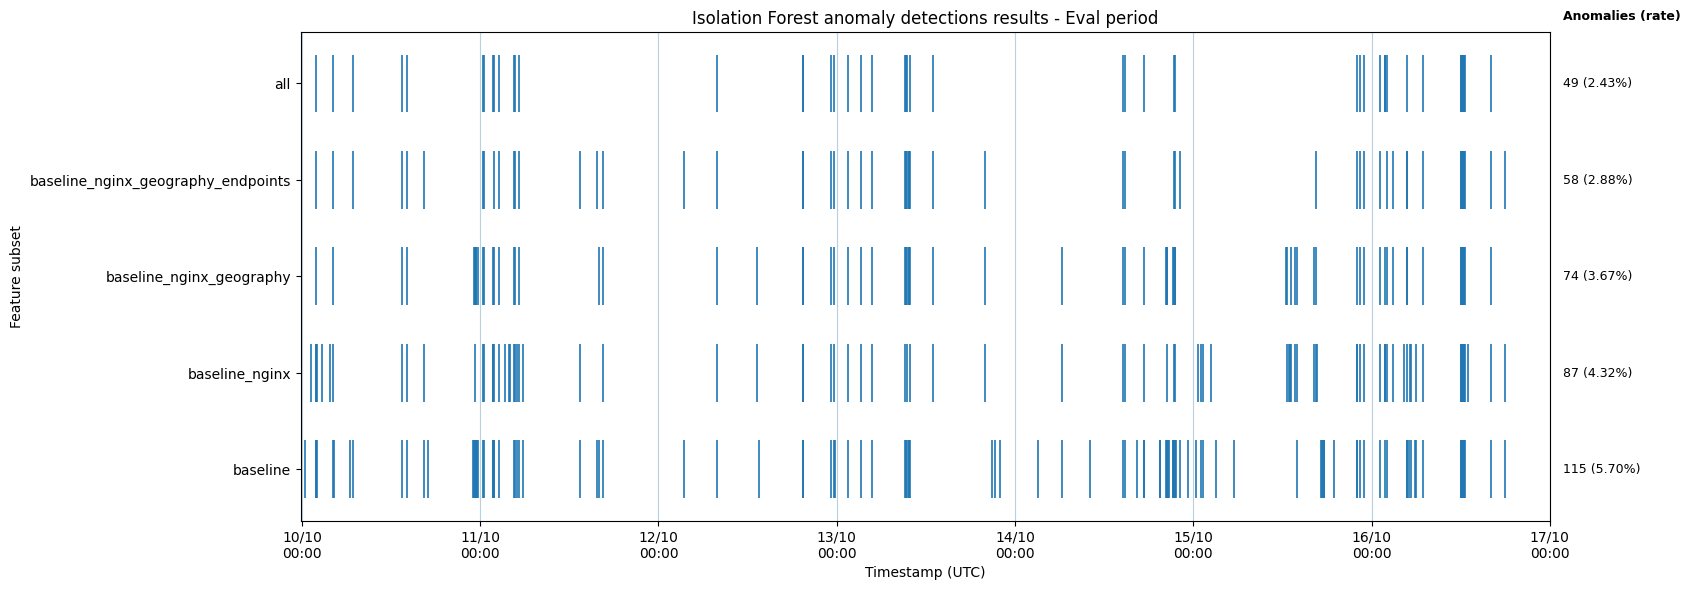

In [126]:
# for evaluation period
eval_flags = plot_anomaly_timeline(feature_experiment_results, timestamps,train_index,eval_index,period="eval")

we can see that the models detect anomalies at the same points in time (several clusters of vertical lines are visible, aligned across all five configurations - notably around October 11, 13, and 16). This is encouraging, as these shared time windows represent strong candidates for further investigation.

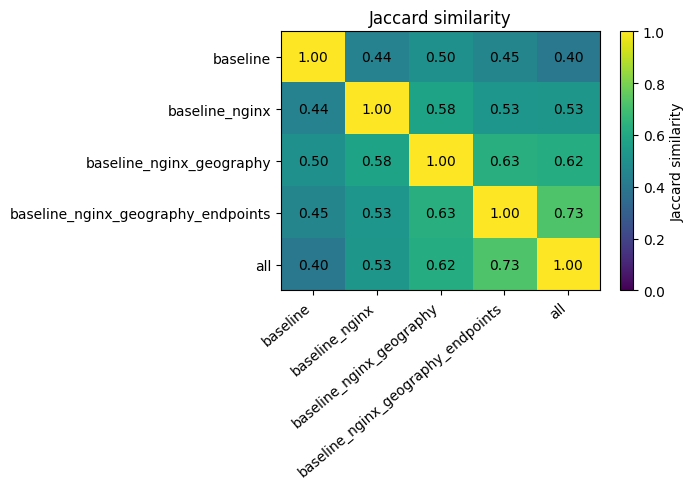

In [180]:
plot_anomaly_overlap(eval_flags)
print()

Comparing sets of anomalies using the Jaccard index reveals that the results depend on the choice of features. The lowest similarity between two distinct configurations is observed between `baseline` and `all` (0.40), while the highest occurs between `baseline_nginx_geography_endpoints` and `all` (0.73).

However, the two most feature-rich configurations yield relatively similar detections, suggesting that their underlying representations lead to more consistent decision-making than that obtained with the minimal feature set (`baseline`).

The Jaccard metric measures only the overlap between detections and does not assess their operational relevance. An analysis of common and specific anomalies follows:

In [129]:
def compare_anomaly_windows(flag_matrix, model_a, model_b):
    """
    Compare anomaly windows detected by two models.

    Returns a DataFrame containing the timestamp and detection status
    for both models.
    """
    comparison = pd.DataFrame({
        model_a: flag_matrix[model_a].astype(bool),
        model_b: flag_matrix[model_b].astype(bool),
    })

    comparison["category"] = "normal_in_both"

    comparison.loc[comparison[model_a] & comparison[model_b],"category"] = "common_anomaly"

    comparison.loc[comparison[model_a] & ~comparison[model_b],"category"] = f"only_anomaly_in_{model_a}"

    comparison.loc[~comparison[model_a] & comparison[model_b],"category"] = f"only_anomaly_in_{model_b}"

    return comparison


# Compare the simplest and richest feature sets
comparison_baseline_all = compare_anomaly_windows(eval_flags,"baseline","all")
print(comparison_baseline_all["category"].value_counts())

print("\n")
# Compare the two richest feature sets
comparison_endpoints_all = compare_anomaly_windows(eval_flags,"baseline_nginx_geography_endpoints","all")
print(comparison_endpoints_all["category"].value_counts())

category
normal_in_both              1899
only_anomaly_in_baseline      68
common_anomaly                47
only_anomaly_in_all            2
Name: count, dtype: int64


category
normal_in_both                                        1954
common_anomaly                                          45
only_anomaly_in_baseline_nginx_geography_endpoints      13
only_anomaly_in_all                                      4
Name: count, dtype: int64


Now, let explore detected anomalies over time for each feature subset by visualizing selected feature (ex. request_count) to better understand the patterns and behaviors associated with anomalous events : 

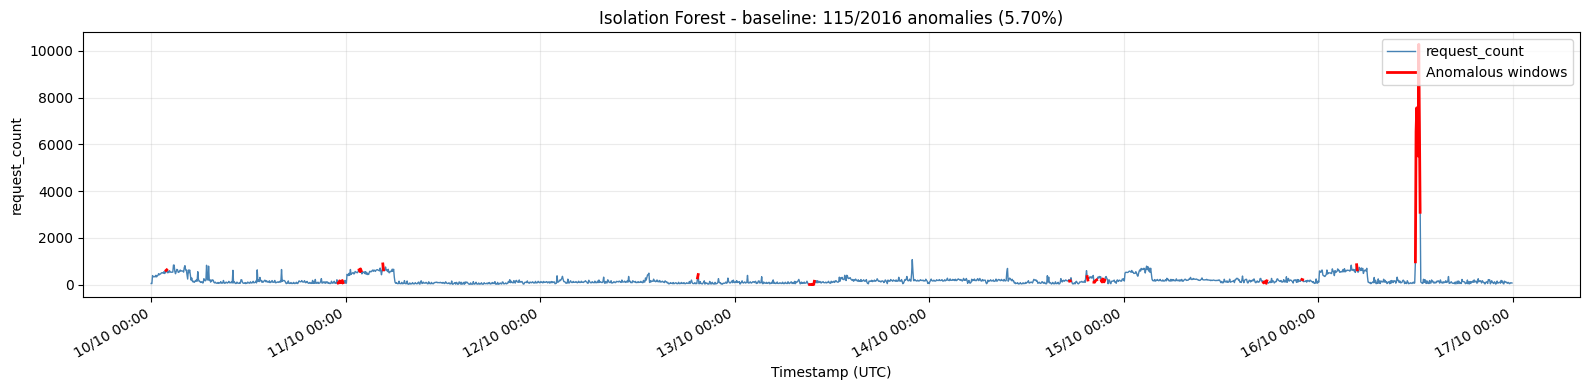

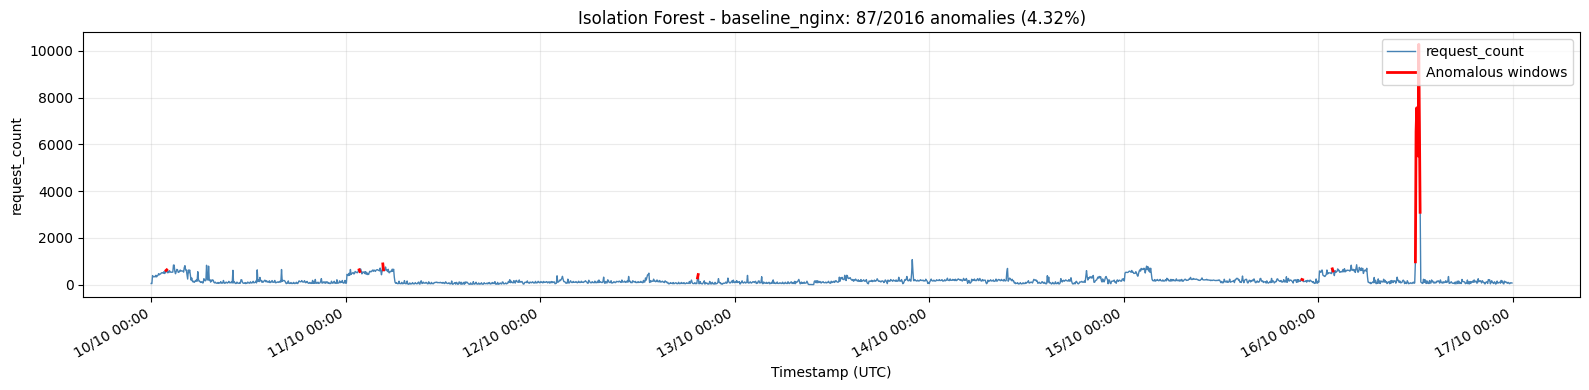

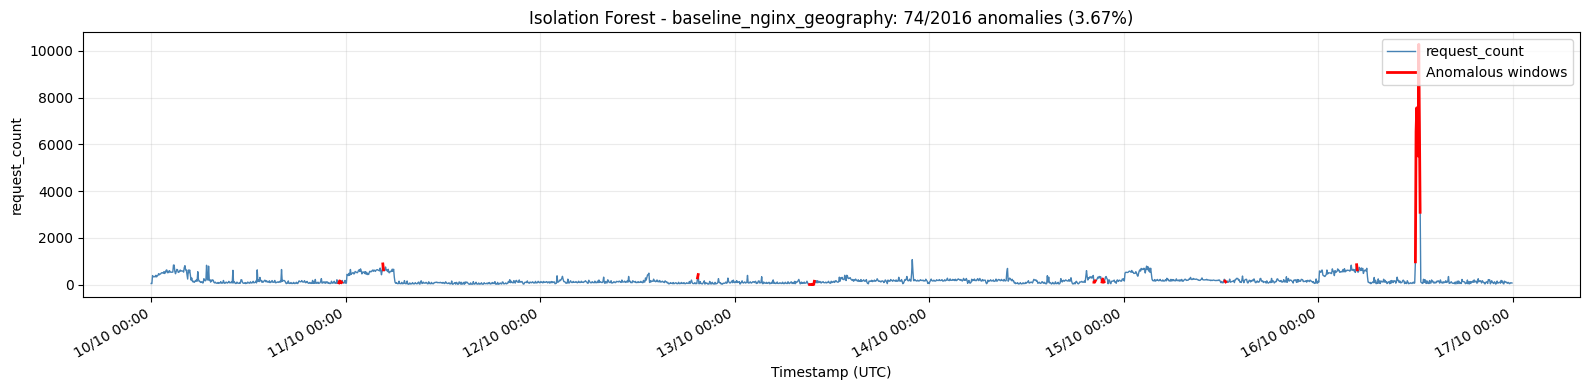

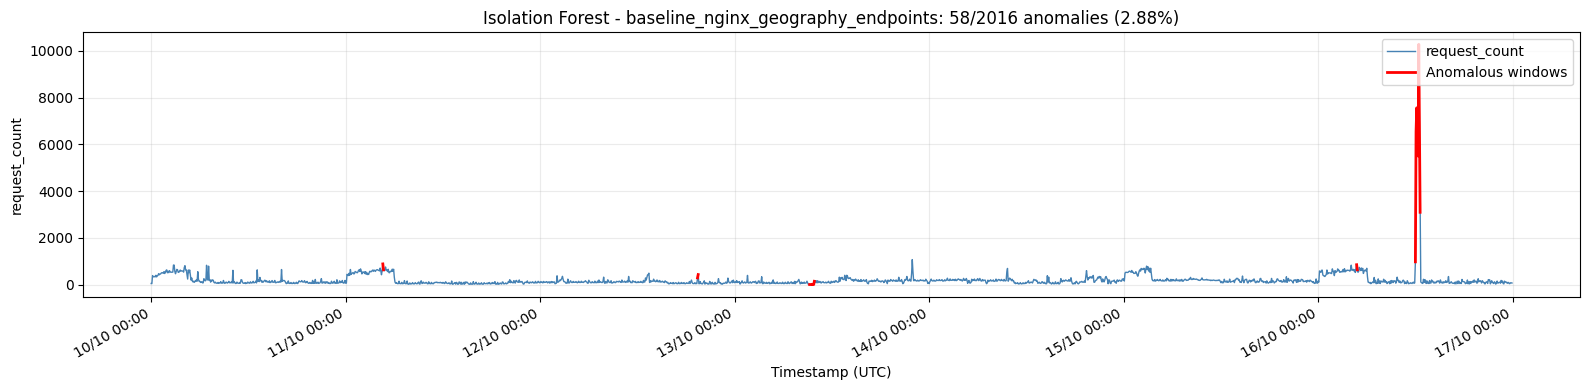

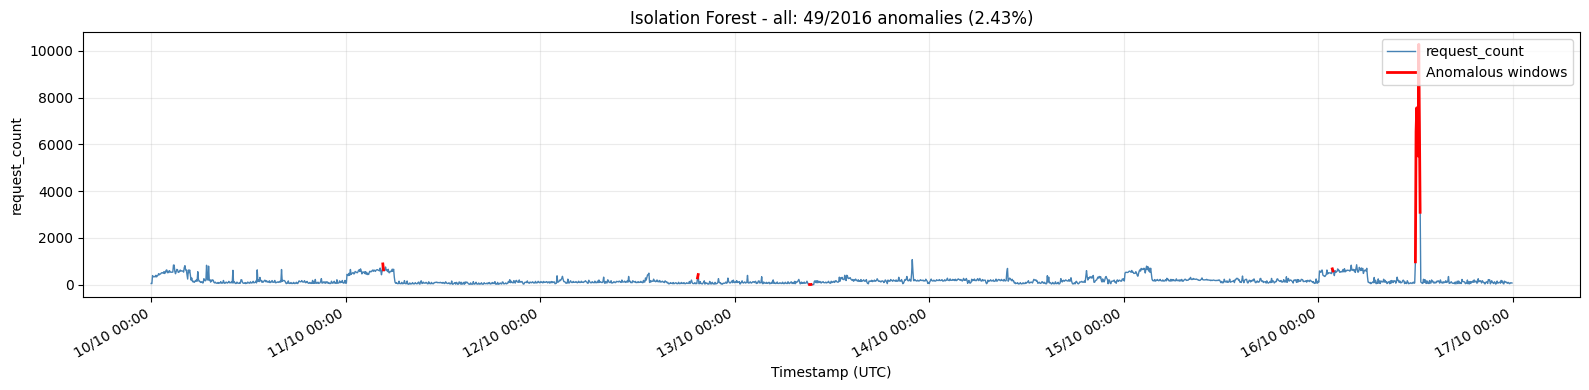

In [174]:
# modify this variable if you want to see another feature or combin (ex. ["request_count","http_5xx_count"])
features_to_plots = ["request_count"]
for name, subset in feature_sets.items():
    results_train, results_eval = feature_experiment_results[name]
    plot_anomaly_features(
        eval_results=results_eval,
        feature_name=name,
        features_df=features_df,
        eval_index=eval_index, # plot on eval period
        features_to_plot=features_to_plots
    )

Most models agree on the big anomalous period around 12h on October 16, suggesting a potentially significant event worth investigating further.

In [175]:

logs_16_october = access_df[(access_df["timestamp"] >= "2026-10-16 12:00:00") &
    (access_df["timestamp"] < "2026-10-16 13:00:00")
].copy()

display(logs_16_october["status_code"].value_counts(normalize=True)*100)

status_code
404    43.126466
400    28.210706
301    25.679249
200      2.72766
405     0.108765
403     0.059714
502     0.055449
500     0.023459
308     0.008531
Name: proportion, dtype: Float64

Looking more closely at the logs around 12h-13h on October 16, I found that approximately 71% of the requests received a 4xx HTTP status code. Investigating the source IP addresses revealed that the traffic originated from an IP associated with IJCLab. This is consistent with the OpenVAS security scan (with bots) performed every Friday, which could explain the anomaly detected by the models.

### 6. Hyperparameter Selection & train/test split: Analysis

The number of trees (`n_estimators`) controls the size of the Isolation Forest ensemble. Scikit-learn uses 100 trees by default, providing a reasonable starting point for this experiment.

The training set currently contains 2016 5-minute windows. Given the absence of ground-truth anomaly labels and the additional computational cost, increasing `n_estimators` is not considered a priority at this stage. A larger ensemble would increase computation time without necessarily improving the operational relevance of the detected anomalies.

Similarly, `contamination` is set to `"auto"` because no ground-truth labels are available to justify a specific expected proportion of anomalies. This is a pragmatic choice rather than a guarantee that the resulting anomaly threshold is optimal.

The experiments therefore focus on comparing feature subsets, measuring agreement between model predictions, and investigating detected events in the original logs. So the default value of `n_estimators=100` and `contamination=True` are retained .

Ultimately, the model selected for deployment will primarily depend on the **feature subset** retained and the **training and evaluation strategy** adopted. One option to investigate later is to train the selected model on the entire available dataset. In that case, additional logs would need to be collected to evaluate the model on a separate, more recent period (what is called the future).